# Домашнее задание: Алгоритмы MCMC (Metropolis Sampling)

## Задача 1
Примените алгоритм Metropolis для генерации выборки из распределения с плотностью:
$$p(x) = 0.3 \cdot N(-4, 2) + 0.7 \cdot N(3, 6)$$
где $N(a, b)$ — плотность нормального распределения со средним $a$ и дисперсией $b$.

Покажите, что гистограмма, построенная по выборке, приближает заданную плотность смеси.

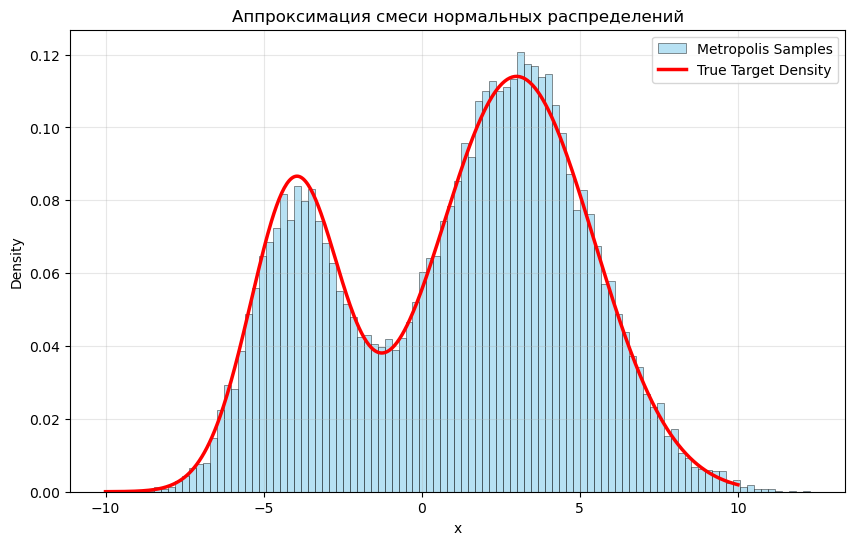

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


w1, mu1, var1 = 0.3, -4, 2
w2, mu2, var2 = 0.7, 3, 6

def target_pdf(x):
    return w1 * stats.norm.pdf(x, mu1, np.sqrt(var1)) + \
           w2 * stats.norm.pdf(x, mu2, np.sqrt(var2))


def metropolis_sampler(n_samples=10000, sigma_proposal=2.0):
    samples = []
    current_x = 0.0  
    
    for _ in range(n_samples):
        proposed_x = np.random.normal(current_x, sigma_proposal)
        
        ratio = target_pdf(proposed_x) / target_pdf(current_x)
        
        if np.random.rand() < ratio:
            current_x = proposed_x
        
        samples.append(current_x)
    
    return np.array(samples)

n_samples = 50000
samples = metropolis_sampler(n_samples=n_samples, sigma_proposal=2.0)

plt.figure(figsize=(10, 6))

plt.hist(samples, bins=100, density=True, alpha=0.6, label='Metropolis Samples', color='skyblue', edgecolor='black', linewidth=0.5)

x_grid = np.linspace(-10, 10, 500)
plt.plot(x_grid, target_pdf(x_grid), 'r', linewidth=2.5, label='True Target Density')

plt.title('Аппроксимация смеси нормальных распределений')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Задача 2
Рассмотрим граф $G=(V,E)$ в виде решетки $10 \times 10$. Вершинам случайным образом приписаны значения 0 и 1 так, что смежные вершины не могут одновременно иметь значение 1 (Hard Square Model).

С помощью алгоритма Metropolis оцените среднее количество единиц $E[I]$ на таком графе.

Среднее количество единиц E[I] (после 20000 шагов burn-in): 23.4487


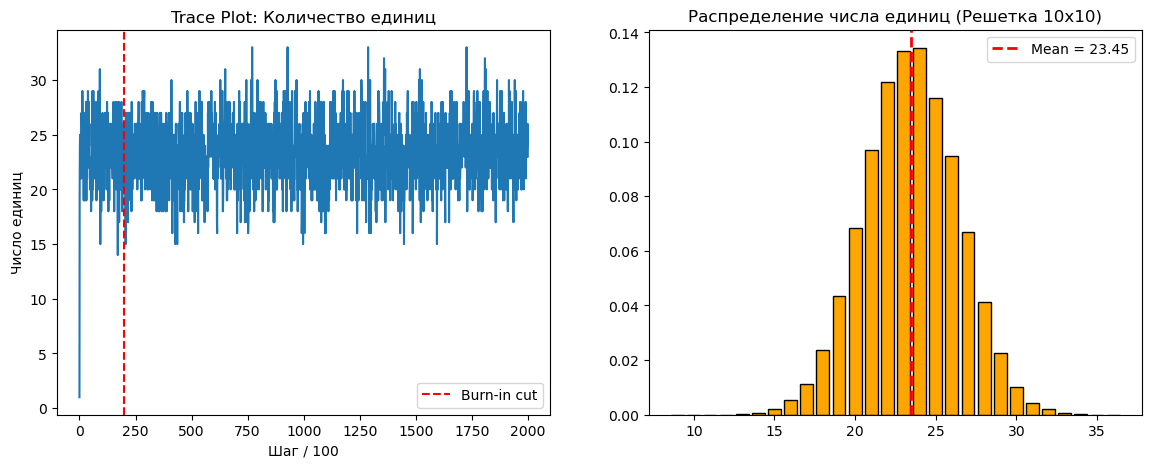

In [19]:
N = 10  

def is_valid(grid, r, c):
    """
    Проверяет, можно ли поставить 1 в ячейку (r, c).
    Возвращает False, если у ячейки есть сосед со значением 1.
    """
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    
    for dr, dc in neighbors:
        nr, nc = r + dr, c + dc
        if 0 <= nr < N and 0 <= nc < N:
            if grid[nr, nc] == 1:
                return False
    return True

def run_metropolis_grid(steps=100000):
    grid = np.zeros((N, N), dtype=int)
    
    ones_history = []  
    current_ones = 0   
    
    for _ in range(steps):
        r, c = np.random.randint(0, N, 2)
        
        current_val = grid[r, c]
        proposed_val = 1 - current_val
        
        accept = False
        
        if proposed_val == 0:
            accept = True
        else:
            if is_valid(grid, r, c):
                accept = True
        
        if accept:
            grid[r, c] = proposed_val
            if proposed_val == 1:
                current_ones += 1
            else:
                current_ones -= 1
        
        ones_history.append(current_ones)
        
    return ones_history, grid

total_steps = 200000
burn_in = 20000 

history, final_grid = run_metropolis_grid(total_steps)
final_samples = history[burn_in:]

mean_ones = np.mean(final_samples)
print(f"Среднее количество единиц E[I] (после {burn_in} шагов burn-in): {mean_ones:.4f}")

plt.figure(figsize=(14, 5))

# 1. Trace plot (Траектория)
plt.subplot(1, 2, 1)
plt.plot(history[::100]) 
plt.title('Trace Plot: Количество единиц')
plt.xlabel('Шаг / 100')
plt.ylabel('Число единиц')
plt.axvline(x=burn_in/100, color='r', linestyle='--', label='Burn-in cut')
plt.legend()

# 2. Гистограмма распределения
plt.subplot(1, 2, 2)
plt.hist(final_samples, bins=np.arange(min(final_samples), max(final_samples)+2)-0.5, 
         density=True, rwidth=0.8, color='orange', edgecolor='black')
plt.axvline(mean_ones, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_ones:.2f}')
plt.title(f'Распределение числа единиц (Решетка {N}x{N})')
plt.legend()

plt.show()

